# Hệ Thống Gợi Ý Món Ăn (Recipe Recommendation DSS)
## Huấn Luyện, Đánh Giá Đa Mô Hình, Trực Quan Hóa Biểu Đồ & Xuất Model



In [7]:
import json, re, random, unicodedata, copy, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfTransformer

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

# Cấu hình hạt giống ngẫu nhiên (Reproducibility)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Thư mục xuất model và kết quả
OUTPUT_DIR = Path('/kaggle/working/recipe_model') if Path('/kaggle/working').exists() else Path('recipe_model')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Tự động dò tìm đường dẫn dữ liệu trên Kaggle hoặc Local
kb_candidates = list(Path('/kaggle/input').rglob('dish_knowledge_base_with_images.json')) if Path('/kaggle/input').exists() else []
syn_candidates = list(Path('/kaggle/input').rglob('ingredients_synonyms_qwen.json')) if Path('/kaggle/input').exists() else []
if Path('dish_knowledge_base_with_images.json').exists(): kb_candidates.append(Path('dish_knowledge_base_with_images.json'))
if Path('ingredients_synonyms_qwen.json').exists(): syn_candidates.append(Path('ingredients_synonyms_qwen.json'))

DATA_PATH = str(kb_candidates[0]) if kb_candidates else 'dish_knowledge_base_with_images.json'
SYN_PATH = str(syn_candidates[0]) if syn_candidates else 'ingredients_synonyms_qwen.json'

print(f"Môi trường: {DEVICE}")
print(f"Dữ liệu món ăn: {DATA_PATH}")
print(f"Từ điển đồng nghĩa: {SYN_PATH}")
print(f"Thư mục lưu trữ: {OUTPUT_DIR.resolve()}")


Môi trường: cuda
Dữ liệu món ăn: /kaggle/input/datasets/phanchuc123/train302/dish_knowledge_base_with_images.json
Từ điển đồng nghĩa: /kaggle/input/datasets/phanchuc123/train302/ingredients_synonyms_qwen.json
Thư mục lưu trữ: /kaggle/working/recipe_model


In [8]:
def normalize(value):
    s = unicodedata.normalize('NFKC', str(value or '')).lower().strip().replace('\u0111', 'd')
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]+', ' ', s)).strip()

# 1. Từ điển từ đồng nghĩa thực phẩm tiếng Việt chuẩn
FOOD_SYNONYMS = {
    'thit lon': 'thit heo', 'thit ba chi': 'ba chi', 'thit ba chi heo': 'ba chi',
    'trung ga': 'trung', 'trung vit': 'trung', 'qua trung': 'trung',
    'hanh kho': 'hanh tim', 'hanh cu': 'hanh tim', 'hanh tim bam': 'hanh tim',
    'dau phong': 'lac', 'ngo': 'bap',
    'suon lon': 'suon heo', 'gio lon': 'gio heo', 'da lon': 'da heo', 'gan lon': 'gan heo', 'tim lon': 'tim heo',
    'bong cai trang': 'cai trang', 'bong cai xanh': 'cai xanh',
    'rau ngo': 'ngo om', 'rau mui': 'ngo ri'
}

# 2. Quy đổi các biến thể gia vị (khắc phục lỗi tiêu vs tiêu xay, muối hạt vs muối tinh...)
SPICE_EXPANSIONS = {
    'tieu xay': 'tieu', 'tieu bot': 'tieu', 'tieu den': 'tieu', 'tieu den xay': 'tieu',
    'hat tieu': 'tieu', 'hat tieu xay': 'tieu', 'tieu hat': 'tieu', 'tieu trang': 'tieu',
    'tieu trang xay': 'tieu', 'tieu so': 'tieu', 'tieu so xay': 'tieu',
    'muoi tinh': 'muoi', 'muoi hat': 'muoi', 'muoi iot': 'muoi', 'muoi bot': 'muoi',
    'duong cat': 'duong', 'duong trang': 'duong', 'duong cat trang': 'duong',
    'toi bam': 'toi', 'cu toi': 'toi', 'toi phi': 'toi',
    'nuoc mam ngon': 'nuoc mam', 'dau thuc vat': 'dau an',
    'ot hiem': 'ot', 'ot trai': 'ot', 'ot sung': 'ot', 'mi chinh': 'bot ngot'
}

synonym_to_canonical = dict(FOOD_SYNONYMS)
synonym_to_canonical.update(SPICE_EXPANSIONS)

if Path(SYN_PATH).exists():
    with open(SYN_PATH, 'r', encoding='utf-8') as f:
        syn_data = json.load(f)
    for item in syn_data:
        raw_ing = normalize(item.get('ingredient', ''))
        for syn in item.get('synonyms', []):
            s = normalize(syn)
            if not s or s == raw_ing: continue
            # Lọc bỏ hallucination của LLM (nước -> muối nở, vani...)
            if s in ('muoi no', 'bot no', 'vani nuoc') and not any(w in raw_ing for w in ('no', 'baking', 'vani')):
                continue
            if s in ('top mo hanh phi', 'nguyen lieu nuoc cham', 'ot chanh tac rau an kem'):
                continue
            if s in raw_ing or set(s.split()).issubset(set(raw_ing.split())):
                synonym_to_canonical[raw_ing] = s

print(f"✓ Đã xây dựng {len(synonym_to_canonical)} quy tắc ánh xạ từ đồng nghĩa chuẩn xác.")

# Tập gia vị tủ bếp mặc định (Default Pantry Staples)
DEFAULT_PANTRY = {
    'muoi', 'muoi tinh', 'muoi hat', 'muoi iot', 'muoi bot',
    'duong', 'duong trang', 'duong cat', 'duong cat trang',
    'nuoc mam', 'nuoc mam ngon',
    'dau an', 'dau thuc vat',
    'tieu', 'tieu xay', 'tieu bot', 'tieu den', 'tieu den xay', 'hat tieu', 'hat tieu xay', 'tieu trang', 'tieu so',
    'toi', 'toi bam', 'cu toi',
    'hanh', 'hanh tim', 'hanh kho', 'hanh cu',
    'nuoc loc', 'nuoc', 'da vien',
    'ot', 'ot trai', 'ot bot', 'ot hiem',
    'hat nem', 'bot ngot', 'bot nem ga', 'mi chinh'
}

# Đọc và chuẩn hóa dữ liệu món ăn
with open(DATA_PATH, encoding='utf-8') as f: raw = json.load(f)
recipes, names = [], {}
for dish in raw:
    items = {}
    for ing in dish.get('ingredients', []):
        name = ing.get('name_vi', '')
        key = normalize(name)
        key = synonym_to_canonical.get(key, key) # Ánh xạ từ chuẩn
        if not key or not re.search('[a-z]', key): continue
        try: weight = float(ing.get('importance') or 1)
        except (ValueError, TypeError): weight = 1.0
        weight = min(3., max(1., weight))
        items[key] = max(items.get(key, 0), weight)
        names.setdefault(key, name)
    if len(items) >= 2:
        recipes.append({
            'id': dish.get('id'), 'name': dish.get('name_vi', ''), 'ingredients': items,
            'category': dish.get('category'), 'url': dish.get('url'), 'image_url': dish.get('image_url')
        })

vocab = {key: i + 1 for i, key in enumerate(sorted(names))} # 0 = padding
keys = [None] + sorted(names)
print(f"✓ Công thức hợp lệ: {len(recipes)} | Số nguyên liệu sau chuẩn hóa: {len(vocab)} (giảm từ 4,096 ban đầu)")

weights = np.zeros((len(recipes), len(vocab)+1), dtype=np.float32)
for i, dish in enumerate(recipes):
    for key, w in dish['ingredients'].items(): weights[i, vocab[key]] = w
row_sums = np.maximum(weights.sum(axis=1), 1e-8)
recipe_ids = [np.flatnonzero(row).tolist() for row in weights]
bin_weights = (weights > 0).astype(np.float32)


✓ Đã xây dựng 936 quy tắc ánh xạ từ đồng nghĩa chuẩn xác.
✓ Công thức hợp lệ: 3253 | Số nguyên liệu sau chuẩn hóa: 3556 (giảm từ 4,096 ban đầu)


In [9]:
# Sinh tập truy vấn nhân tạo (Synthetic Queries) có thêm nhiễu thực tế
TRAIN_PER_DISH, VAL_PER_DISH, TEST_PER_DISH = 8, 2, 2
rng = random.Random(SEED)
splits = {'train': [], 'val': [], 'test': []}
all_ids = list(range(1, len(vocab)+1))

for label, ids in enumerate(recipe_ids):
    seen, generated = set(), []
    outside = list(set(all_ids) - set(ids))
    for _ in range(120):
        n_keep = rng.randint(1, len(ids)-1)
        query = rng.sample(ids, n_keep)
        if outside and rng.random() < 0.35:
            query += rng.sample(outside, min(len(outside), rng.randint(1, 2)))
        q = tuple(sorted(set(query)))
        if q not in seen:
            seen.add(q); generated.append((q, label))
        if len(generated) >= TRAIN_PER_DISH + VAL_PER_DISH + TEST_PER_DISH: break
    rng.shuffle(generated)
    splits['test'].extend(generated[:min(TEST_PER_DISH, max(0, len(generated)-1))])
    remain = generated[min(TEST_PER_DISH, max(0, len(generated)-1)):]
    nval = min(VAL_PER_DISH, max(0, len(remain)-1))
    splits['val'].extend(remain[:nval]); splits['train'].extend(remain[nval:])

for k, v in splits.items(): print(f"Tập {k}: {len(v)} mẫu")

class Queries(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(batch):
    lengths = max(len(q) for q, _ in batch)
    x = torch.zeros((len(batch), lengths), dtype=torch.long)
    for i, (q, _) in enumerate(batch): x[i, :len(q)] = torch.tensor(q)
    return x, torch.tensor([y for _, y in batch], dtype=torch.long)

train_loader = DataLoader(Queries(splits['train']), batch_size=128, shuffle=True, collate_fn=collate)
val_loader = DataLoader(Queries(splits['val']), batch_size=128, collate_fn=collate)
test_loader = DataLoader(Queries(splits['test']), batch_size=128, collate_fn=collate)


Tập train: 26024 mẫu
Tập val: 6506 mẫu
Tập test: 6506 mẫu


In [10]:
class IngredientSetEncoder(nn.Module):
    def __init__(self, n_ing, n_recipes, dim=96, hidden=192, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(n_ing + 1, dim, padding_idx=0)
        self.net = nn.Sequential(
            nn.Linear(dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, n_recipes)
        )
    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        pooled = (self.embedding(x) * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.net(pooled)

EPOCHS, LR, PATIENCE = 25, 0.001, 4
model = IngredientSetEncoder(len(vocab), len(recipes)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()
best_loss, best_state, stale = float('inf'), None, 0

train_loss_history = []
val_loss_history = []

print("=== BẮT ĐẦU HUẤN LUYỆN INGREDIENT SET ENCODER ===")
for epoch in range(1, EPOCHS+1):
    model.train(); total = count = 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); optimizer.step()
        total += loss.item()*len(y); count += len(y)
    
    model.eval(); val_total = val_count = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            val_total += loss_fn(model(x), y).item()*len(y); val_count += len(y)
            
    tl = total / count; vl = val_total / val_count
    train_loss_history.append(tl); val_loss_history.append(vl)
    print(f"Epoch {epoch:02d} | Train Loss: {tl:.4f} | Val Loss: {vl:.4f}")
    
    if vl < best_loss - 1e-4:
        best_loss, best_state, stale = vl, copy.deepcopy(model.state_dict()), 0
    else:
        stale += 1
        if stale >= PATIENCE:
            print(f"-> Early stopping tại epoch {epoch} (Best Val Loss: {best_loss:.4f})")
            break

model.load_state_dict(best_state)


=== BẮT ĐẦU HUẤN LUYỆN INGREDIENT SET ENCODER ===
Epoch 01 | Train Loss: 7.8057 | Val Loss: 6.8778
Epoch 02 | Train Loss: 5.0600 | Val Loss: 4.5217
Epoch 03 | Train Loss: 2.9378 | Val Loss: 3.6773
Epoch 04 | Train Loss: 2.0997 | Val Loss: 3.3463
Epoch 05 | Train Loss: 1.6821 | Val Loss: 3.1945
Epoch 06 | Train Loss: 1.4168 | Val Loss: 3.1318
Epoch 07 | Train Loss: 1.2424 | Val Loss: 3.0939
Epoch 08 | Train Loss: 1.1116 | Val Loss: 3.0941
Epoch 09 | Train Loss: 1.0229 | Val Loss: 3.1018
Epoch 10 | Train Loss: 0.9378 | Val Loss: 3.1085
Epoch 11 | Train Loss: 0.8792 | Val Loss: 3.1212
-> Early stopping tại epoch 11 (Best Val Loss: 3.0939)


<All keys matched successfully>

In [11]:
class MeanSAGE(nn.Module):
    def __init__(self, nodes, dim=64):
        super().__init__()
        self.emb = nn.Embedding(nodes, dim)
        self.layers = nn.ModuleList([nn.Linear(2*dim, dim), nn.Linear(2*dim, dim)])
    def forward(self, edge_index):
        h = self.emb.weight
        src, dst = edge_index
        for layer in self.layers:
            agg = torch.zeros_like(h); agg.index_add_(0, dst, h[src])
            deg = torch.bincount(dst, minlength=h.size(0)).to(h.dtype).unsqueeze(1).clamp(min=1)
            h = torch.relu(layer(torch.cat([h, agg/deg], dim=1)))
        return h
    def score(self, h, pairs):
        return (h[pairs[:,0]] * h[pairs[:,1]]).sum(dim=1) / (h.size(1)**0.5)

num_dishes = len(recipes); num_nodes = num_dishes + len(vocab)
positive = [(d, num_dishes + ing - 1) for d, ids in enumerate(recipe_ids) for ing in ids]
all_positive = set(positive)
rng_graph = np.random.default_rng(SEED)
order = rng_graph.permutation(len(positive)); shuffled = [positive[i] for i in order]
n_val = int(.1*len(shuffled)); n_test = int(.1*len(shuffled))
val_pos = shuffled[:n_val]; test_pos = shuffled[n_val:n_val+n_test]; train_edges = shuffled[n_val+n_test:]
cut = int(.8*len(train_edges)); message_pairs, train_pos = train_edges[:cut], train_edges[cut:]

def to_edges(pairs):
    directed = pairs + [(b,a) for a,b in pairs]
    return torch.tensor(directed, dtype=torch.long, device=DEVICE).T.contiguous()

message_edges = to_edges(message_pairs)
def sample_negatives(count, rng):
    out, used = [], set()
    while len(out) < count:
        pair = (int(rng.integers(num_dishes)), num_dishes + int(rng.integers(len(vocab))))
        if pair not in all_positive and pair not in used:
            used.add(pair); out.append(pair)
    return out

val_neg = sample_negatives(len(val_pos), rng_graph)
test_neg = sample_negatives(len(test_pos), rng_graph)

sage = MeanSAGE(num_nodes).to(DEVICE)
sage_opt = torch.optim.Adam(sage.parameters(), lr=0.01)
sage_crit = nn.BCEWithLogitsLoss()

def evaluate_link(pairs_pos, pairs_neg, h):
    pos = torch.tensor(pairs_pos, device=DEVICE); neg = torch.tensor(pairs_neg, device=DEVICE)
    with torch.no_grad():
        sp = torch.sigmoid(sage.score(h, pos)).cpu().numpy()
        sn = torch.sigmoid(sage.score(h, neg)).cpu().numpy()
    y = np.concatenate([np.ones_like(sp), np.zeros_like(sn)])
    scores = np.concatenate([sp, sn])
    order = np.argsort(-scores); sorted_y = y[order]
    n_pos = len(sp); n_neg = len(sn)
    tpr = np.cumsum(sorted_y) / n_pos; fpr = np.cumsum(1 - sorted_y) / n_neg
    auc = float(np.trapz(tpr, fpr)) if hasattr(np, 'trapz') else float(np.trapezoid(tpr, fpr))
    prec = np.cumsum(sorted_y) / np.arange(1, len(y)+1)
    ap = float((prec * sorted_y).sum() / n_pos)
    return {'auc': auc, 'average_precision': ap, 'tpr': tpr, 'fpr': fpr}

gnn_loss_history = []
gnn_val_auc_history = []

print("=== BẮT ĐẦU HUẤN LUYỆN GRAPHSAGE LINK PREDICTION ===")
for epoch in range(1, 41):
    sage.train(); sage_opt.zero_grad()
    h = sage(message_edges)
    train_neg = sample_negatives(len(train_pos), rng_graph)
    pos_t = torch.tensor(train_pos, device=DEVICE); neg_t = torch.tensor(train_neg, device=DEVICE)
    loss = sage_crit(sage.score(h, pos_t), torch.ones(len(train_pos), device=DEVICE)) +            sage_crit(sage.score(h, neg_t), torch.zeros(len(train_neg), device=DEVICE))
    loss.backward(); sage_opt.step()
    gnn_loss_history.append(loss.item())
    
    if epoch % 5 == 0 or epoch == 40:
        sage.eval()
        with torch.no_grad(): h_eval = sage(message_edges)
        vm = evaluate_link(val_pos, val_neg, h_eval)
        gnn_val_auc_history.append((epoch, vm['auc']))
        print(f"GNN Epoch {epoch:02d} | Loss: {loss.item():.4f} | Val AUC: {vm['auc']:.4f}")

sage.eval()
with torch.no_grad(): h_final = sage(message_edges)
gnn_test_res = evaluate_link(test_pos, test_neg, h_final)
print(f"✓ GNN Held-out Test: ROC-AUC = {gnn_test_res['auc']:.4f} | AP = {gnn_test_res['average_precision']:.4f}")

# Chuẩn bị node embedding serving
full_edges = to_edges(positive)
with torch.no_grad(): h_serving = sage(full_edges)
dish_emb = h_serving[:num_dishes].clone()
ing_emb = h_serving[num_dishes:].clone()
dish_norms = torch.norm(dish_emb, dim=1, keepdim=True).clamp(min=1e-8)

def gnn_recipe_scores(x):
    scores = []
    for row in x.cpu().numpy():
        ids = [i-1 for i in row if i != 0]
        if not ids: scores.append(np.zeros(num_dishes, dtype=np.float32)); continue
        q = ing_emb[ids].mean(dim=0, keepdim=True)
        q = q / torch.norm(q, dim=1, keepdim=True).clamp(min=1e-8)
        sim = (dish_emb @ q.T).squeeze(1) / dish_norms.squeeze(1)
        sim = ((sim + 1) / 2).clamp(0, 1)
        scores.append(sim.cpu().numpy())
    return np.stack(scores)


=== BẮT ĐẦU HUẤN LUYỆN GRAPHSAGE LINK PREDICTION ===
GNN Epoch 05 | Loss: 1.2911 | Val AUC: 0.7581


/tmp/ipykernel_50/213854345.py:56: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc = float(np.trapz(tpr, fpr)) if hasattr(np, 'trapz') else float(np.trapezoid(tpr, fpr))


GNN Epoch 10 | Loss: 1.1743 | Val AUC: 0.8097
GNN Epoch 15 | Loss: 1.0666 | Val AUC: 0.8231
GNN Epoch 20 | Loss: 1.0098 | Val AUC: 0.8453
GNN Epoch 25 | Loss: 0.9972 | Val AUC: 0.8830
GNN Epoch 30 | Loss: 0.9836 | Val AUC: 0.8886
GNN Epoch 35 | Loss: 0.9856 | Val AUC: 0.8974
GNN Epoch 40 | Loss: 0.9740 | Val AUC: 0.8990
✓ GNN Held-out Test: ROC-AUC = 0.8986 | AP = 0.9131


In [13]:
def features_batch(x):
    present = np.zeros((len(x), len(vocab)+1), dtype=np.float32)
    for i, row in enumerate(x.cpu().numpy()): present[i, row[row != 0]] = 1
    matched = present @ (weights > 0).astype(np.float32).T
    coverage = matched / np.maximum(present.sum(axis=1, keepdims=True), 1)
    cbf = (present @ weights.T) / row_sums[None, :]
    main = ((weights > 0) & (weights == weights.max(axis=1, keepdims=True))).astype(np.float32)
    main_count = main.sum(axis=1)
    main_score = np.divide(present @ main.T, main_count[None, :],
                           out=np.ones((len(x), len(recipes)), dtype=np.float32),
                           where=main_count[None, :] > 0)
    with torch.no_grad(): logits = model(x.to(DEVICE)).cpu().numpy()
    lo, hi = logits.min(axis=1, keepdims=True), logits.max(axis=1, keepdims=True)
    deep = (logits-lo) / np.maximum(hi-lo, 1e-8)
    return deep, cbf, coverage, main_score, matched

def collect_features(loader):
    model.eval(); feature_parts = []; labels = []
    for x, y in loader:
        feature_parts.append(features_batch(x)); labels.append(y.numpy())
    return tuple(np.concatenate([part[i] for part in feature_parts]) for i in range(5)), np.concatenate(labels)

def compute_metrics(scores, matched, labels):
    scores = np.where(matched > 0, scores, -np.inf)
    ranking = np.argsort(-scores, axis=1)[:, :10]
    
    hits = {f'Hit@{k}': round(float((ranking[:, :k] == labels[:, None]).any(axis=1).mean()), 4) for k in (1, 5, 10)}
    # Mean Reciprocal Rank (MRR)
    matches = (ranking == labels[:, None])
    reciprocal_ranks = np.zeros(len(labels))
    for i in range(len(labels)):
        nz = np.flatnonzero(matches[i])
        if len(nz) > 0:
            reciprocal_ranks[i] = 1.0 / (nz[0] + 1)
    hits['MRR'] = round(float(reciprocal_ranks.mean()), 4)
    return hits

def evaluate_features(features, labels, coeff):
    deep, cbf, coverage, main, matched = features
    scores = coeff[0]*deep + coeff[1]*cbf + coeff[2]*coverage + coeff[3]*main
    return compute_metrics(scores, matched, labels)

# 1. Tìm trọng số tối ưu trên Validation Set
val_features, val_labels = collect_features(val_loader)
candidates = [(a/4, b/4, c/4, (4-a-b-c)/4) for a in range(1, 5) for b in range(5-a) for c in range(5-a-b)]
validation_grid = [(evaluate_features(val_features, val_labels, c)['Hit@10'], c) for c in candidates]
best_score, best_coeff = max(validation_grid, key=lambda t: t[0])
print(f"✓ Trọng số tối ưu Deep Hybrid: {best_coeff} (Hit@10 Val: {best_score:.4f})")

# 2. Đánh giá tất cả các mô hình trên cùng Test Set
test_features, test_labels = collect_features(test_loader)
deep, cbf, coverage, main, matched = test_features

# TF-IDF & Jaccard Baselines
tfidf_trans = TfidfTransformer(norm='l2')
recipe_tfidf = tfidf_trans.fit_transform(bin_weights).toarray()

test_queries = [row[row != 0] for x, _ in test_loader for row in x.cpu().numpy()]
N_test = len(test_queries)
Q_mat = np.zeros((N_test, len(vocab)+1), dtype=np.float32)
for i, q in enumerate(test_queries): Q_mat[i, q] = 1.0

# Batching to compute Jaccard & TF-IDF
CHUNK = 1000
jaccard_all = []; tfidf_all = []
d_lens = bin_weights.sum(axis=1, keepdims=True).T
for start in range(0, N_test, CHUNK):
    end = min(start + CHUNK, N_test)
    sub_q = Q_mat[start:end]
    sub_inter = sub_q @ bin_weights.T
    sub_union = sub_q.sum(axis=1, keepdims=True) + d_lens - sub_inter
    jaccard_all.append(sub_inter / np.maximum(sub_union, 1e-8))
    
    sub_tfidf_q = tfidf_trans.transform(sub_q).toarray()
    tfidf_all.append(sub_tfidf_q @ recipe_tfidf.T)

jaccard_scores = np.concatenate(jaccard_all, axis=0)
tfidf_scores = np.concatenate(tfidf_all, axis=0)

# Random Matching Baseline
# Random Matching Baseline
rng_rand = np.random.default_rng(SEED)

TOP_K = 10
random_ranking = np.full(
    (N_test, TOP_K),
    -1,
    dtype=int
)

for i in range(N_test):
    cand = np.flatnonzero(matched[i] > 0)

    if len(cand) > 0:
        shuffled = rng_rand.permutation(cand)[:TOP_K]
        random_ranking[i, :len(shuffled)] = shuffled

# Hit@K
random_metrics = {
    f'Hit@{k}': round(
        float(
            (random_ranking[:, :k] == test_labels[:, None])
            .any(axis=1)
            .mean()
        ),
        4
    )
    for k in (1, 5, 10)
}

# MRR
random_matches = (
    random_ranking == test_labels[:, None]
)

random_mrr = np.zeros(N_test)

for i in range(N_test):
    nz = np.flatnonzero(random_matches[i])

    if len(nz) > 0:
        random_mrr[i] = 1.0 / (nz[0] + 1)

random_metrics['MRR'] = round(
    float(random_mrr.mean()), 4
)

print("Random Matching:", random_metrics)

# Bảng tổng hợp các mô hình
results_dict = {
    '1. Random Matching': random_metrics,
    '2. CBF (Importance Weighted)': evaluate_features(test_features, test_labels, (0, 1, 0, 0)),
    '3. TF-IDF + Cosine': compute_metrics(tfidf_scores, matched, test_labels),
    '4. Jaccard Similarity (IoU)': compute_metrics(jaccard_scores, matched, test_labels),
    '5. Ingredient Set Encoder': evaluate_features(test_features, test_labels, (1, 0, 0, 0)),
    '6. Previous Hybrid (50/50)': evaluate_features(test_features, test_labels, (0.5, 0.5, 0, 0)),
    '7. Main-aware Equal Blend': evaluate_features(test_features, test_labels, (0.25, 0.25, 0.25, 0.25)),
    '8. Deep Hybrid (Đề xuất tối ưu)': evaluate_features(test_features, test_labels, best_coeff)
}

df_comparison = pd.DataFrame(results_dict).T
print("\n================ BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ================")
print(df_comparison.to_string())


✓ Trọng số tối ưu Deep Hybrid: (0.25, 0.25, 0.5, 0.0) (Hit@10 Val: 0.8595)
Random Matching: {'Hit@1': 0.0232, 'Hit@5': 0.0667, 'Hit@10': 0.0965, 'MRR': 0.0421}

================ BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ================
                                  Hit@1   Hit@5  Hit@10     MRR
1. Random Matching               0.0232  0.0667  0.0965  0.0421
2. CBF (Importance Weighted)     0.3246  0.6107  0.6969  0.4440
3. TF-IDF + Cosine               0.6611  0.7943  0.8383  0.7184
4. Jaccard Similarity (IoU)      0.6740  0.7959  0.8380  0.7275
5. Ingredient Set Encoder        0.5650  0.7090  0.7601  0.6260
6. Previous Hybrid (50/50)       0.5429  0.7370  0.7962  0.6269
7. Main-aware Equal Blend        0.5489  0.7158  0.7804  0.6202
8. Deep Hybrid (Đề xuất tối ưu)  0.7241  0.8209  0.8540  0.7660


✓ Đã lưu toàn bộ biểu đồ đánh giá tại: /kaggle/working/recipe_model/model_comparison_charts.png


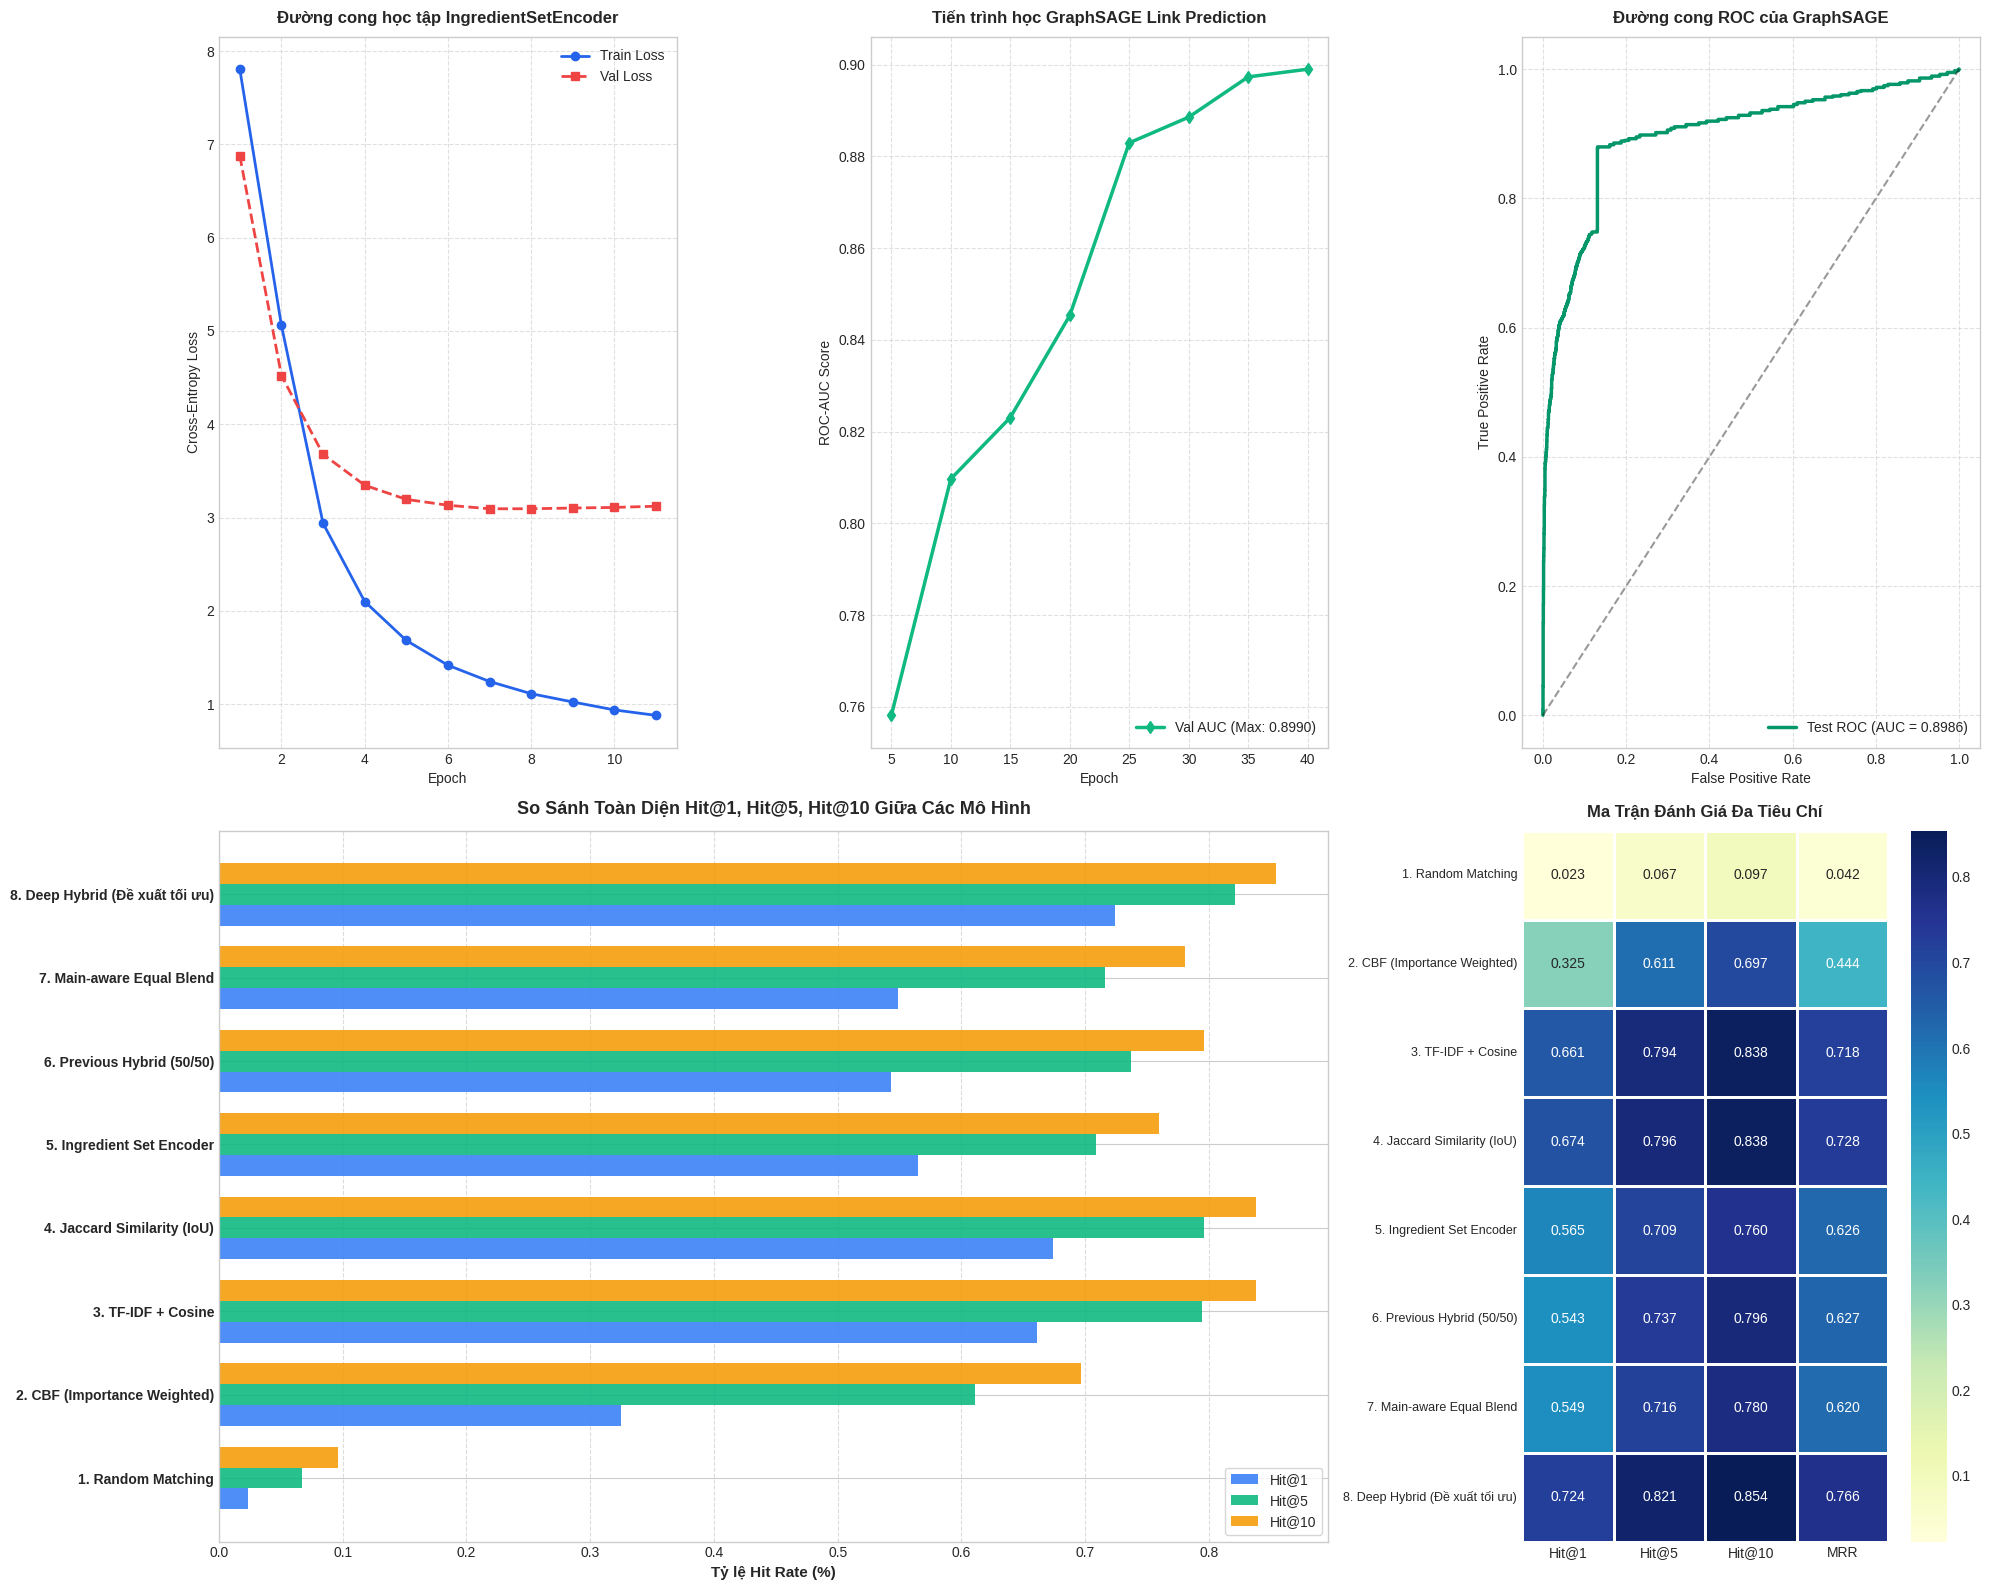

In [14]:
# THIẾT LẬP GIAO DIỆN BIỂU ĐỒ CHUYÊN NGHIỆP
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(20, 16))

# BIỂU ĐỒ 1: Đường cong học tập của IngredientSetEncoder (Loss)
ax1 = plt.subplot(2, 3, 1)
epochs_range = range(1, len(train_loss_history) + 1)
ax1.plot(epochs_range, train_loss_history, 'o-', color='#2563eb', label='Train Loss', linewidth=2)
ax1.plot(epochs_range, val_loss_history, 's--', color='#ef4444', label='Val Loss', linewidth=2)
ax1.set_title('Đường cong học tập IngredientSetEncoder', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss'); ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# BIỂU ĐỒ 2: GNN Link Prediction (ROC & Val AUC)
ax2 = plt.subplot(2, 3, 2)
gnn_epochs = [x[0] for x in gnn_val_auc_history]
gnn_aucs = [x[1] for x in gnn_val_auc_history]
ax2.plot(gnn_epochs, gnn_aucs, 'd-', color='#10b981', linewidth=2.5, label=f'Val AUC (Max: {max(gnn_aucs):.4f})')
ax2.set_title('Tiến trình học GraphSAGE Link Prediction', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('ROC-AUC Score'); ax2.legend(loc='lower right')
ax2.grid(True, linestyle='--', alpha=0.6)

# BIỂU ĐỒ 3: ROC Curve của GraphSAGE
ax3 = plt.subplot(2, 3, 3)
ax3.plot(gnn_test_res['fpr'], gnn_test_res['tpr'], color='#059669', linewidth=2.5, label=f'Test ROC (AUC = {gnn_test_res["auc"]:.4f})')
ax3.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax3.set_title('Đường cong ROC của GraphSAGE', fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel('False Positive Rate'); ax3.set_ylabel('True Positive Rate'); ax3.legend(loc='lower right')
ax3.grid(True, linestyle='--', alpha=0.6)

# BIỂU ĐỒ 4: So sánh Grouped Bar Chart giữa các mô hình (Hit@1, Hit@5, Hit@10)
ax4 = plt.subplot(2, 3, (4, 5))
models = list(df_comparison.index)
x_pos = np.arange(len(models))
width = 0.25

rects1 = ax4.barh(x_pos - width, df_comparison['Hit@1'], width, label='Hit@1', color='#3b82f6', alpha=0.9)
rects2 = ax4.barh(x_pos, df_comparison['Hit@5'], width, label='Hit@5', color='#10b981', alpha=0.9)
rects3 = ax4.barh(x_pos + width, df_comparison['Hit@10'], width, label='Hit@10', color='#f59e0b', alpha=0.9)

ax4.set_yticks(x_pos)
ax4.set_yticklabels(models, fontsize=10, fontweight='semibold')
ax4.set_xlabel('Tỷ lệ Hit Rate (%)', fontsize=11, fontweight='bold')
ax4.set_title('So Sánh Toàn Diện Hit@1, Hit@5, Hit@10 Giữa Các Mô Hình', fontsize=13, fontweight='bold', pad=12)
ax4.legend(loc='lower right', frameon=True)
ax4.grid(True, axis='x', linestyle='--', alpha=0.7)

# BIỂU ĐỒ 5: Heatmap Ma trận Tiêu chí Đánh giá (Criteria Evaluation Matrix)
ax5 = plt.subplot(2, 3, 6)
criteria_matrix = df_comparison[['Hit@1', 'Hit@5', 'Hit@10', 'MRR']].copy()
sns.heatmap(criteria_matrix, annot=True, fmt='.3f', cmap='YlGnBu', cbar=True, ax=ax5, linewidths=1)
ax5.set_title('Ma Trận Đánh Giá Đa Tiêu Chí', fontsize=12, fontweight='bold', pad=10)
ax5.set_yticklabels(criteria_matrix.index, rotation=0, fontsize=9)

plt.tight_layout()
chart_path = OUTPUT_DIR / 'model_comparison_charts.png'
plt.savefig(chart_path, dpi=300, bbox_inches='tight')
print(f"✓ Đã lưu toàn bộ biểu đồ đánh giá tại: {chart_path}")
plt.show()


In [15]:
# XÂY DỰNG KNOWLEDGE GRAPH & HÀM GỢI Ý SERVING
from collections import defaultdict

kg = defaultdict(list); inv_kg = defaultdict(list)
for d in recipes:
    did = d['id']
    for ing_name, imp in d['ingredients'].items():
        kg[did].append({'rel': 'requires', 'target': ing_name, 'importance': imp})
        inv_kg[ing_name].append({'rel': 'required_by', 'target': did, 'importance': imp})
    if d['category']:
        kg[did].append({'rel': 'category', 'target': d['category']})
        inv_kg[d['category']].append({'rel': 'category_of', 'target': did})

recipe_idx_by_id = {d['id']: i for i, d in enumerate(recipes)}

def graph_candidates(ingredient_ids, category=None):
    candidates = set()
    for iid in ingredient_ids:
        k = keys[iid]
        for edge in inv_kg.get(k, []):
            did = edge['target']
            if did in recipe_idx_by_id: candidates.add(recipe_idx_by_id[did])
    if category is not None:
        cat_matches = {recipe_idx_by_id[edge['target']] for edge in inv_kg.get(category, []) if edge['target'] in recipe_idx_by_id}
        candidates &= cat_matches
    return candidates

def recommend(ingredients, top_k=5, method='hybrid', assume_pantry=True):
    all_inputs = list(ingredients)
    resolved = [synonym_to_canonical.get(normalize(s), normalize(s)) for s in all_inputs]
    ids = sorted({vocab[key] for key in resolved if key in vocab})
    optional = set(DEFAULT_PANTRY) if assume_pantry else set()
    
    result = {'ready': [], 'needs_shopping': []}
    if not ids: return result
    
    x = torch.tensor([ids]).to(DEVICE)
    deep, cbf, coverage, main, matched = features_batch(x)
    
    configs = {
        'hybrid': best_coeff,
        'cbf': (0, 1, 0, 0),
        'encoder': (1, 0, 0, 0),
        'main_aware': (0.25, 0.25, 0.25, 0.25)
    }
    coeff = configs.get(method, best_coeff)
    scores = sum(w * f[0] for w, f in zip(coeff, (deep, cbf, coverage, main)))
    
    candidates_set = graph_candidates(ids)
    for idx in np.argsort(-scores):
        if idx not in candidates_set: continue
        dish = recipes[idx]; have = set(ids)
        missing_keys = [k for k in dish['ingredients'] if vocab[k] not in have]
        missing_required = [k for k in missing_keys if k not in optional]
        group = 'ready' if not missing_required else 'needs_shopping'
        max_imp = max(dish['ingredients'].values())
        result[group].append({
            'dish': dish['name'], 'score': round(float(scores[idx]), 4),
            'matched': [names[k] for k in dish['ingredients'] if vocab[k] in have],
            'missing_required': [names[k] for k in missing_required],
            'input_utilization': round(float(coverage[0, idx]) * 100, 1)
        })
    result['ready'] = result['ready'][:top_k]
    result['needs_shopping'] = result['needs_shopping'][:top_k]
    return result

# Chạy thử nghiệm với món kinh điển
sample_q = ['thịt heo', 'cà chua', 'hành tây']
res_test = recommend(sample_q, top_k=3, method='hybrid', assume_pantry=True)
print(f"\n=== TEST GỢI Ý VỚI: {sample_q} ===")
print("NẤU ĐƯỢC NGAY (READY):")
for r in res_test['ready']: print(f"  - {r['dish']} (score: {r['score']}, tận dụng: {r['input_utilization']}%)")
print("CẦN MUA THÊM (NEEDS SHOPPING):")
for r in res_test['needs_shopping']: print(f"  - {r['dish']} (score: {r['score']}, thiếu: {r['missing_required']})")



=== TEST GỢI Ý VỚI: ['thịt heo', 'cà chua', 'hành tây'] ===
NẤU ĐƯỢC NGAY (READY):
  - Thịt heo chiên tỏi ớt (score: 0.5828, tận dụng: 66.7%)
  - Nước ép cà chua không cần máy (score: 0.5269, tận dụng: 33.3%)
  - Thịt kho nước mắm (score: 0.4115, tận dụng: 33.3%)
CẦN MUA THÊM (NEEDS SHOPPING):
  - mì spaghetti (score: 0.8276, thiếu: ['Cà rốt', 'Mì ý', 'Tương cà', 'Bơ'])
  - Thịt cừu hầm (score: 0.6428, thiếu: ['Thịt cừu', 'Ớt sừng xanh', 'Sốt cà chua'])
  - Xà lách (salad) trộn dầu giấm (score: 0.6107, thiếu: ['Xà lách', 'Dưa leo', 'Ngò rí', 'Giấm gạo', 'Tương ớt'])


In [16]:
# XUẤT MODEL VÀ TOÀN BỘ ARTIFACTS
print("=== XUẤT MÔ HÌNH VÀ BỘ DỮ LIỆU ĐÁNH GIÁ ===")

# 1. Lưu checkpoint Encoder
checkpoint = {
    'state_dict': model.state_dict(),
    'vocab': vocab,
    'synonym_to_canonical': synonym_to_canonical,
    'default_pantry': list(DEFAULT_PANTRY),
    'best_coeff': best_coeff,
    'recipes': recipes,
    'names': names
}
torch.save(checkpoint, OUTPUT_DIR / 'ingredient_set_encoder.pt')
print("✓ Đã lưu Encoder Checkpoint:", OUTPUT_DIR / 'ingredient_set_encoder.pt')

# 2. Lưu GraphSAGE
torch.save({
    'sage_state_dict': sage.state_dict(),
    'h_serving': h_serving.cpu(),
    'graph_weight': 0.0
}, OUTPUT_DIR / 'graphsage.pt')
print("✓ Đã lưu GNN Checkpoint:", OUTPUT_DIR / 'graphsage.pt')

# 3. Lưu Knowledge Graph
with open(OUTPUT_DIR / 'knowledge_graph.json', 'w', encoding='utf-8') as f:
    json.dump({
        'kg': kg, 'names': names,
        'categories': sorted({d['category'] for d in recipes if d['category']})
    }, f, ensure_ascii=False)
print("✓ Đã lưu Knowledge Graph:", OUTPUT_DIR / 'knowledge_graph.json')

# 4. Lưu bảng so sánh hiệu năng CSV & JSON
df_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', encoding='utf-8-sig')
with open(OUTPUT_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(results_dict, f, ensure_ascii=False, indent=2)
print("✓ Đã lưu Bảng so sánh metrics:", OUTPUT_DIR / 'model_comparison.csv')

print(f"\n🎉 HOÀN TẤT 100%! Bạn có thể tải thư mục {OUTPUT_DIR.resolve()} về máy để sử dụng cho Web hoặc nộp bài.")


=== XUẤT MÔ HÌNH VÀ BỘ DỮ LIỆU ĐÁNH GIÁ ===
✓ Đã lưu Encoder Checkpoint: /kaggle/working/recipe_model/ingredient_set_encoder.pt
✓ Đã lưu GNN Checkpoint: /kaggle/working/recipe_model/graphsage.pt
✓ Đã lưu Knowledge Graph: /kaggle/working/recipe_model/knowledge_graph.json
✓ Đã lưu Bảng so sánh metrics: /kaggle/working/recipe_model/model_comparison.csv

🎉 HOÀN TẤT 100%! Bạn có thể tải thư mục /kaggle/working/recipe_model về máy để sử dụng cho Web hoặc nộp bài.
